```
data-mining-project/
├── data/               # Fișierul CSV brut (cerut obligatoriu la predare)
├── notebooks/          # Notebook-ul de explorare și grafice (exportat din Colab)
├── src/                # Scripturi Python curate (.py) pentru antrenare și evaluare
├── requirements.txt    # Librăriile folosite (pandas, scikit-learn, xgboost, shap)
└── README.md           # Rezumatul executiv pentru recrutori (cu graficele cheie)
```

#### **TITLE: Tech & AI Salary Correlates: Predictive Modeling in the Remote Work Era**

> Among employed respondents to the 2025 Stack Overflow Developer Survey in selected European countries, how are annualized compensation levels associated with experience, role, work arrangement, and AI adoption, and how accurately can models predict compensation?

This is a self-selected, cross-sectional survey. Findings describe associations among respondents; they do not establish causal effects or represent all European tech workers. The `Employed` category does not identify full-time status.



Choosing cols from big dataset

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor, plot_tree

In [2]:
cols_to_keep = [
    'ConvertedCompYearly',      # Self-reported annualized compensation, converted to USD
    'Country',                  # Selected European countries
    'Employment',               # Employed category; not a full-time indicator
    'DevType',                  # Multi-select developer role(s)
    'WorkExp',                  # Years of professional work experience
    'YearsCode',                # Total years of coding experience
    'RemoteWork',               # Current work arrangement
    'OrgSize',                  # Employer size category
    'Industry',                 # Employer industry
    'ICorPM',                   # Individual contributor or people manager
    'EdLevel',                  # Education category
    'AISelect',                 # AI tool usage
    'AIAgents',                 # AI agent usage
    'LanguageHaveWorkedWith',   # Multi-select programming languages
    'PlatformHaveWorkedWith'    # Multi-select platforms
]

In [3]:
project_root = Path.cwd()
if not (project_root / 'data').is_dir():
    project_root = project_root.parent

data_path = project_root / 'data' / 'survey_results_public.csv'
if not data_path.is_file():
    raise FileNotFoundError(f'Could not find survey CSV at {data_path.resolve()}')

# pandas converts the survey's NA markers to missing values; preserve those as missing.
df_raw = pd.read_csv(data_path, usecols=cols_to_keep)
print(f'Loaded: {data_path.resolve()}')
print(f'Raw rows: {len(df_raw):,}')
print(f'Raw columns loaded: {len(df_raw.columns)}')

Loaded: C:\Users\Teodor Turcanu\Desktop\ai-tech-salary-prediction\data\survey_results_public.csv
Raw rows: 49,123
Raw columns loaded: 15


In [4]:
europe_countries = [
    'United Kingdom of Great Britain and Northern Ireland', 'Germany', 'France',
    'Netherlands', 'Poland', 'Spain', 'Italy', 'Sweden', 'Switzerland', 'Belgium',
    'Austria', 'Norway', 'Denmark', 'Finland', 'Ireland', 'Portugal', 'Czech Republic',
    'Romania', 'Greece', 'Hungary', 'Ukraine', 'Bulgaria', 'Croatia', 'Slovakia',
    'Serbia', 'Lithuania', 'Slovenia', 'Estonia', 'Latvia', 'Luxembourg', 'Iceland',
    'Cyprus', 'Malta', 'Bosnia and Herzegovina', 'Albania', 'North Macedonia',
    'Republic of Moldova', 'Montenegro', 'Belarus'
]

In [5]:
df_europe = df_raw.loc[df_raw['Country'].isin(europe_countries)].copy()
print(f'Selected European-country rows: {len(df_europe):,}')
print(f'Countries represented: {df_europe["Country"].nunique()}')

Selected European-country rows: 16,424
Countries represented: 38


In [6]:
df_employed = df_europe.loc[df_europe['Employment'].eq('Employed')].copy()
print(f'Rows in the Employed category (not necessarily full-time): {len(df_employed):,}')

Rows in the Employed category (not necessarily full-time): 12,009


Primary target preparation: keep positive reported salaries for the main nominal analysis. Apply the $8,000-$500,000 bounds only as a sensitivity sample; the bounds do not prove a response is erroneous.

In [7]:
salary = pd.to_numeric(df_employed['ConvertedCompYearly'], errors='coerce')
salary_missing = salary.isna()
salary_nonpositive = salary.notna() & salary.le(0)
salary_below_8000 = salary.gt(0) & salary.lt(8_000)
salary_above_500000 = salary.gt(500_000)

print('Salary exclusions before filtering:')
print(f'  Missing or non-numeric: {salary_missing.sum():,}')
print(f'  Zero or negative: {salary_nonpositive.sum():,}')
print(f'  Positive but below $8,000: {salary_below_8000.sum():,}')
print(f'  Above $500,000: {salary_above_500000.sum():,}')

valid_salary = salary.notna() & salary.gt(0)
df_all_positive = df_employed.loc[valid_salary].copy()
df_all_positive['ConvertedCompYearly'] = salary.loc[valid_salary]

# Use this transparent plausibility range for the primary model; retain all positive values for sensitivity checks.
primary_range = df_all_positive['ConvertedCompYearly'].between(8_000, 500_000)
df_clean = df_all_positive.loc[primary_range].copy()
print(f'All positive-salary sample for sensitivity analysis: {len(df_all_positive):,}')
print(f'Primary plausibility-range sample ($8,000-$500,000): {len(df_clean):,}')

review_columns = ['ConvertedCompYearly', 'Country', 'DevType', 'WorkExp', 'YearsCode']
print('Lowest positive salaries:')
display(df_all_positive.nsmallest(10, 'ConvertedCompYearly')[review_columns])
print('Highest positive salaries:')
display(df_all_positive.nlargest(10, 'ConvertedCompYearly')[review_columns])

Salary exclusions before filtering:
  Missing or non-numeric: 2,420
  Zero or negative: 0
  Positive but below $8,000: 458
  Above $500,000: 30
All positive-salary sample for sensitivity analysis: 9,589
Primary plausibility-range sample ($8,000-$500,000): 9,101
Lowest positive salaries:


,ConvertedCompYearly,Country,DevType,WorkExp,YearsCode
47176,1.0,Ukraine,"Developer, QA or test",12.0,12.0
14487,2.0,Denmark,Cloud infrastructure engineer,12.0,4.0
45146,2.0,Germany,"Developer, full-stack",11.0,20.0
32022,5.0,Ukraine,Data scientist,1.0,3.0
10074,6.0,Spain,Project manager,15.0,15.0
26182,6.0,Romania,Academic researcher,5.0,7.0
32510,10.0,Ukraine,Data or business analyst,2.0,4.0
34142,10.0,Germany,"Developer, AI apps or physical AI",3.0,10.0
22399,15.0,Albania,"Senior executive (C-suite, VP, etc.)",47.0,50.0
11958,17.0,Ukraine,"Developer, back-end",3.0,3.0


Highest positive salaries:


,ConvertedCompYearly,Country,DevType,WorkExp,YearsCode
28700,33552715.0,Ukraine,"Developer, full-stack",20.0,27.0
43143,18387548.0,Poland,Financial analyst or engineer,10.0,10.0
45971,13921760.0,Netherlands,"Senior executive (C-suite, VP, etc.)",30.0,10.0
38007,1740220.0,Finland,"Architect, software or solutions",20.0,28.0
31876,1555205.0,Denmark,AI/ML engineer,9.0,11.0
11938,1497556.0,United Kingdom of Great Britain and Northern I...,"Founder, technology or otherwise",9.0,12.0
42326,1361415.0,United Kingdom of Great Britain and Northern I...,Engineering manager,15.0,19.0
38750,1239929.0,Switzerland,Engineering manager,35.0,45.0
48839,1225273.0,United Kingdom of Great Britain and Northern I...,"Developer, full-stack",26.0,35.0
4583,1160147.0,Latvia,"Developer, full-stack",30.0,30.0


In [8]:
na_summary = pd.DataFrame({
    'Missing_Values': df_clean.isnull().sum(),
    'Percent_NA(%)': (df_clean.isnull().sum() / len(df_clean) * 100).round(2)
}).sort_values(by='Percent_NA(%)', ascending=False)
print("\nNew report of missing values:")
print(na_summary)


New report of missing values:
                        Missing_Values  Percent_NA(%)
PlatformHaveWorkedWith            2132          23.43
LanguageHaveWorkedWith             550           6.04
AIAgents                           457           5.02
AISelect                           194           2.13
ICorPM                             134           1.47
WorkExp                             69           0.76
RemoteWork                          33           0.36
YearsCode                           26           0.29
Industry                            12           0.13
EdLevel                              6           0.07
OrgSize                              6           0.07
DevType                              0           0.00
Employment                           0           0.00
Country                              0           0.00
ConvertedCompYearly                  0           0.00


Primary plausibility-range nominal compensation (USD):


count      9101.00
mean      82867.71
std       47796.64
min        8000.00
1%        11983.00
5%        26198.00
25%       52207.00
50%       74878.00
75%      102106.00
95%      166093.00
99%      258669.00
max      464059.00
Name: ConvertedCompYearly, dtype: float64

All-positive sensitivity-sample summary:


count        9589.00
mean        88149.91
std        419973.74
min             1.00
1%            202.00
5%           8657.20
25%         48726.00
50%         71929.00
75%         99773.00
95%        167390.00
99%        281144.56
max      33552715.00
Name: ConvertedCompYearly, dtype: float64

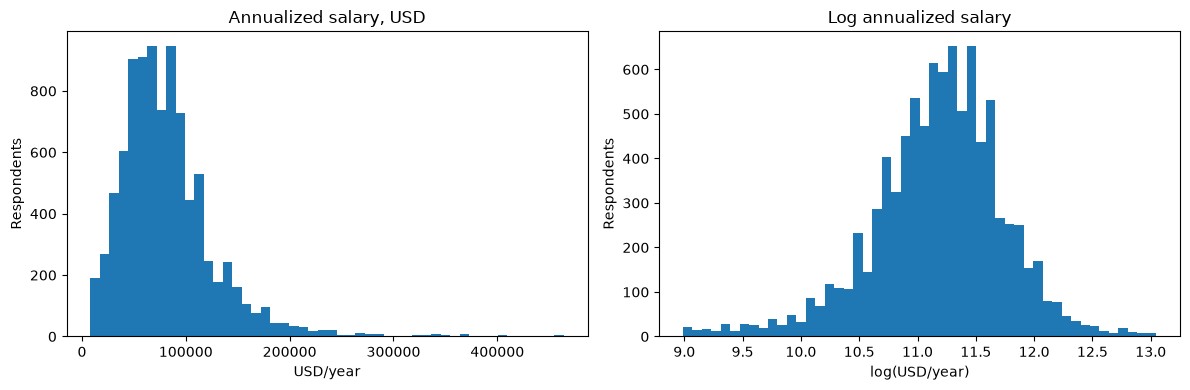

In [9]:
print('Primary plausibility-range nominal compensation (USD):')
display(df_clean['ConvertedCompYearly'].describe(percentiles=[.01, .05, .25, .50, .75, .95, .99]).round(2))
print('All-positive sensitivity-sample summary:')
display(df_all_positive['ConvertedCompYearly'].describe(percentiles=[.01, .05, .25, .50, .75, .95, .99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_clean['ConvertedCompYearly'], bins=50)
axes[0].set(title='Annualized salary, USD', xlabel='USD/year', ylabel='Respondents')
axes[1].hist(np.log(df_clean['ConvertedCompYearly']), bins=50)
axes[1].set(title='Log annualized salary', xlabel='log(USD/year)', ylabel='Respondents')
plt.tight_layout()

The primary modeling sample uses a transparent $8,000-$500,000 plausibility range. The full positive-salary sample remains available for sensitivity analysis. The bounds are not proof that excluded values are erroneous: the raw positive-salary sample includes values as low as $1 and as high as $33,552,715, which should be reviewed and discussed. Stack Overflow reports salary conversion to USD using the exchange rate on June 25, 2025, and asks hourly-paid respondents to estimate a yearly equivalent. Describe the target as self-reported annualized compensation converted to USD, not necessarily gross pay.

Secondary analysis: 2025 Eurostat household-consumption price-level normalization. This subset must not replace the nominal-salary sample.

In [10]:
# Sursa oficială: Eurostat - Price level indices (tec00120 / prc_ppp_ind_1), anul 2025, EU27 = 100 (împărțit la 100)
# Indicator: Household final consumption expenditure (HFCE)
price_level_index_2025 = {
    'Switzerland': 1.81,      # 181.0% of EU27 average
    'Iceland': 1.84,          # 183.7%
    'Luxembourg': 1.32,       # 132.0%
    'Denmark': 1.40,          # 140.2%
    'Norway': 1.38,           # 138.4%
    'Ireland': 1.36,          # 136.0%
    'Finland': 1.21,          # 121.0%
    'Sweden': 1.21,           # 121.0%
    'Netherlands': 1.20,      # 120.4%
    'Austria': 1.19,          # 119.0%
    'Belgium': 1.16,          # 116.0%
    'Germany': 1.09,          # 109.1%
    'France': 1.06,           # 106.4%
    'Italy': 0.98,            # 98.0%
    'Estonia': 0.98,          # 97.8%
    'Malta': 0.96,            # 95.8%
    'Cyprus': 0.92,           # 91.6%
    'Spain': 0.91,            # 91.1%
    'Slovenia': 0.91,         # 91.1%
    'Portugal': 0.85,         # 85.3%
    'Greece': 0.84,           # 84.0%
    'Czech Republic': 0.82,   # 82.0%
    'Lithuania': 0.81,        # 81.4%
    'Slovakia': 0.81,         # 81.4%
    'Latvia': 0.81,           # 80.6%
    'Hungary': 0.78,          # 78.0%
    'Croatia': 0.78,          # 78.0%
    'Poland': 0.73,           # 73.0%
    'Montenegro': 0.66,       # 66.0%
    'Romania': 0.65,          # 65.0%
    'Bulgaria': 0.63          # 63.0%
}

# Keep this as a separate subset so unmapped countries remain in the nominal analysis.
df_ppp = df_clean.copy()
df_ppp['Price_Index'] = df_ppp['Country'].map(price_level_index_2025)
ppp_unmapped = df_ppp.loc[df_ppp['Price_Index'].isna(), 'Country'].value_counts()
print('Countries excluded from the secondary price-level analysis:')
display(ppp_unmapped)
print(f'Price-index coverage: {df_ppp["Price_Index"].notna().mean():.1%}')

df_ppp = df_ppp.loc[df_ppp['Price_Index'].notna()].copy()
if not df_ppp['Price_Index'].gt(0).all():
    raise ValueError('All mapped price indices must be positive.')

# This is a price-level-normalized salary proxy, not a direct currency PPP conversion.
df_ppp['Salary_EU27_PriceLevel_Adjusted_USD'] = (
    df_ppp['ConvertedCompYearly'] / df_ppp['Price_Index']
).round(2)
print(f'Rows in nominal sample: {len(df_clean):,}')
print(f'Rows in price-level subset: {len(df_ppp):,}')
display(df_ppp['Salary_EU27_PriceLevel_Adjusted_USD'].describe().round(2))

Countries excluded from the secondary price-level analysis:


Country
United Kingdom of Great Britain and Northern Ireland    1257
Ukraine                                                  367
Serbia                                                    63
Bosnia and Herzegovina                                    13
Belarus                                                   13
Albania                                                    6
Republic of Moldova                                        3
Name: count, dtype: int64

Price-index coverage: 81.1%
Rows in nominal sample: 9,101
Rows in price-level subset: 7,379


count      7379.00
mean      75283.29
std       39201.74
min        5771.74
25%       50651.68
50%       69033.88
75%       89741.26
max      484457.14
Name: Salary_EU27_PriceLevel_Adjusted_USD, dtype: float64

## Feature engineering and missing-value audit

The survey's `NA` markers are read as missing. Missing multi-select answers stay unknown; they are not automatically treated as zero or as evidence of non-use. Role-family indicators can overlap because the source role question allows multiple selections.

In [11]:
df_model = df_clean.copy()

for column in ['WorkExp', 'YearsCode']:
    original_nonmissing = df_model[column].notna()
    numeric_values = pd.to_numeric(df_model[column], errors='coerce')
    parse_failures = original_nonmissing & numeric_values.isna()
    print(f'{column}: non-numeric values converted to missing = {parse_failures.sum():,}')
    df_model[column] = numeric_values
    df_model[f'Missing_{column}'] = df_model[column].isna().astype(int)

def parse_multi_select(value):
    if pd.isna(value):
        return None
    return {item.strip() for item in str(value).split(';') if item.strip()}

def multi_select_count(value):
    tokens = parse_multi_select(value)
    return np.nan if tokens is None else len(tokens)

df_model['Language_Count'] = df_model['LanguageHaveWorkedWith'].map(multi_select_count)
df_model['Platform_Count'] = df_model['PlatformHaveWorkedWith'].map(multi_select_count)
df_model['Missing_Language_Answer'] = df_model['LanguageHaveWorkedWith'].isna().astype(int)
df_model['Missing_Platform_Answer'] = df_model['PlatformHaveWorkedWith'].isna().astype(int)

cloud_provider_tokens = {
    'Amazon Web Services (AWS)',
    'Microsoft Azure',
    'Google Cloud',
}

def uses_major_cloud(value):
    tokens = parse_multi_select(value)
    if tokens is None:
        return np.nan
    return int(not tokens.isdisjoint(cloud_provider_tokens))

df_model['Uses_Major_Cloud'] = df_model['PlatformHaveWorkedWith'].map(uses_major_cloud)

role_families = {
    'Data_AI': {
        'AI/ML engineer', 'Applied scientist', 'Data engineer',
        'Data or business analyst', 'Data scientist',
        'Developer, AI apps or physical AI',
    },
    'Software_Engineering': {
        'Architect, software or solutions',
        'Developer, back-end', 'Developer, desktop or enterprise applications',
        'Developer, embedded applications or devices', 'Developer, front-end',
        'Developer, full-stack', 'Developer, game or graphics', 'Developer, mobile',
        'Developer, QA or test', 'Developer, AI apps or physical AI',
    },
    'DevOps_Cloud': {
        'Cloud infrastructure engineer', 'DevOps engineer or professional',
        'Database administrator or engineer', 'System administrator',
    },
    'Management': {
        'Engineering manager', 'Founder, technology or otherwise',
        'Product manager', 'Project manager', 'Senior executive (C-suite, VP, etc.)',
    },
}
mapped_role_tokens = set().union(*role_families.values())
observed_role_tokens = {
    token
    for value in df_model['DevType'].dropna()
    for token in parse_multi_select(value)
}
other_role_tokens = observed_role_tokens - mapped_role_tokens
print('Role labels grouped as other/specialized; review this mapping:')
print(sorted(other_role_tokens))

for family, tokens in role_families.items():
    column = f'Role_{family}'
    df_model[column] = df_model['DevType'].map(
        lambda value: np.nan if pd.isna(value)
        else int(not parse_multi_select(value).isdisjoint(tokens))
    )

df_model['Role_OtherOrSpecialized'] = df_model['DevType'].map(
    lambda value: np.nan if pd.isna(value)
    else int(not parse_multi_select(value).isdisjoint(other_role_tokens))
)

feature_missing = (
    df_model.drop(columns=['ConvertedCompYearly'])
    .isna()
    .sum()
    .rename('Missing_Count')
    .to_frame()
)
feature_missing['Missing_Percent'] = (
    feature_missing['Missing_Count'] / len(df_model) * 100
).round(2)
display(feature_missing.sort_values('Missing_Percent', ascending=False))

WorkExp: non-numeric values converted to missing = 0
YearsCode: non-numeric values converted to missing = 0
Role labels grouped as other/specialized; review this mapping:
['Academic researcher', 'Cybersecurity or InfoSec professional', 'Financial analyst or engineer', 'Other (please specify):', 'Student', 'Support engineer or analyst', 'UX, Research Ops or UI design professional']


,Missing_Count,Missing_Percent
Platform_Count,2132,23.43
PlatformHaveWorkedWith,2132,23.43
Uses_Major_Cloud,2132,23.43
Language_Count,550,6.04
LanguageHaveWorkedWith,550,6.04
AIAgents,457,5.02
AISelect,194,2.13
ICorPM,134,1.47
WorkExp,69,0.76
RemoteWork,33,0.36


## Model preparation and evaluation

The first models use nominal annualized USD compensation and the full positive-salary sample. Imputation and one-hot encoding are fit inside each training fold. The final test set is held out from cross-validation and model selection.

In [12]:
continuous_features = ['WorkExp', 'YearsCode', 'Language_Count', 'Platform_Count']
binary_features = [
    'Uses_Major_Cloud', 'Missing_WorkExp', 'Missing_YearsCode',
    'Missing_Language_Answer', 'Missing_Platform_Answer',
    'Role_Data_AI', 'Role_Software_Engineering', 'Role_DevOps_Cloud',
    'Role_Management', 'Role_OtherOrSpecialized',
]
categorical_features = [
    'Country', 'RemoteWork', 'OrgSize', 'Industry', 'ICorPM',
    'EdLevel', 'AISelect', 'AIAgents',
]
feature_columns = continuous_features + binary_features + categorical_features
X = df_model[feature_columns].copy()
y = df_model['ConvertedCompYearly'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

def make_preprocessor():
    continuous_pipeline = SimpleImputer(strategy='median')
    binary_pipeline = SimpleImputer(strategy='most_frequent')
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('one_hot', OneHotEncoder(
            handle_unknown='ignore', drop='first', min_frequency=10,
            sparse_output=False,
        )),
    ])
    return ColumnTransformer(
        transformers=[
            ('continuous', continuous_pipeline, continuous_features),
            ('binary', binary_pipeline, binary_features),
            ('categorical', categorical_pipeline, categorical_features),
        ],
        remainder='drop',
    )

def make_log_salary_model(regressor):
    return TransformedTargetRegressor(
        regressor=Pipeline([
            ('preprocessor', make_preprocessor()),
            ('regressor', regressor),
        ]),
        func=np.log,
        inverse_func=np.exp,
    )

models = {
    'Median baseline': DummyRegressor(strategy='median'),
    'OLS on log salary': make_log_salary_model(LinearRegression()),
    'Regression tree on log salary': make_log_salary_model(
        DecisionTreeRegressor(max_depth=5, min_samples_leaf=30, random_state=42)
    ),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}
cv_rows = []
for name, estimator in models.items():
    scores = cross_validate(
        estimator, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, error_score='raise',
    )
    cv_rows.append({
        'Model': name,
        'CV_MAE_USD': -scores['test_MAE'].mean(),
        'CV_RMSE_USD': -scores['test_RMSE'].mean(),
        'CV_R2': scores['test_R2'].mean(),
    })
cv_results = pd.DataFrame(cv_rows).sort_values('CV_MAE_USD')
display(cv_results.round(3))

fitted_models = {}
for name, estimator in models.items():
    fitted_models[name] = estimator.fit(X_train, y_train)

def evaluate_predictions(y_true, predictions, training_mean):
    absolute_error = np.abs(np.asarray(y_true) - np.asarray(predictions))
    rae_denominator = np.abs(np.asarray(y_true) - training_mean).sum()
    return {
        'MAE_USD': mean_absolute_error(y_true, predictions),
        'RMSE_USD': mean_squared_error(y_true, predictions) ** 0.5,
        'RAE': absolute_error.sum() / rae_denominator,
        'R2': r2_score(y_true, predictions),
    }

test_rows = []
for name, estimator in fitted_models.items():
    test_rows.append({
        'Model': name,
        **evaluate_predictions(y_test, estimator.predict(X_test), y_train.mean()),
    })
test_results = pd.DataFrame(test_rows).sort_values('MAE_USD')
display(test_results.round(3))

,Model,CV_MAE_USD,CV_RMSE_USD,CV_R2
1,OLS on log salary,23313.878,37582.576,0.371
2,Regression tree on log salary,26960.316,41708.634,0.225
0,Median baseline,32733.902,48025.890,-0.028


,Model,MAE_USD,RMSE_USD,RAE,R2
1,OLS on log salary,23707.914,38489.962,0.695,0.387
2,Regression tree on log salary,27632.105,42587.074,0.810,0.249
0,Median baseline,33492.998,49990.676,0.982,-0.034


## OLS diagnostics

The inferential OLS model below uses the training partition only. HC3 standard errors are used to reduce sensitivity of inference to heteroscedasticity. The VIF table focuses on continuous experience/technology-count predictors, especially `WorkExp` versus `YearsCode`; it is not a universal pass/fail test.

OLS adjusted R-squared (log salary): 0.4802
                                                                      Coefficient  HC3_p_value
categorical__Country_Ukraine                                               -0.849     1.82e-75
categorical__Country_Switzerland                                            0.539     1.92e-48
categorical__OrgSize_Less than 20 employees                                -0.242     1.45e-38
categorical__Country_Italy                                                 -0.447     2.47e-38
categorical__Country_Greece                                                -0.618      5.3e-30
categorical__Country_Poland                                                 -0.43      3.1e-24
categorical__Country_Spain                                                 -0.372     4.11e-23
categorical__RemoteWork_Remote                                              0.144     2.89e-22
continuous__WorkExp                                                        0.0116     6.35e-22
catego

,Feature,VIF
0,WorkExp,3.421
1,YearsCode,3.420
2,Language_Count,1.264
3,Platform_Count,1.261


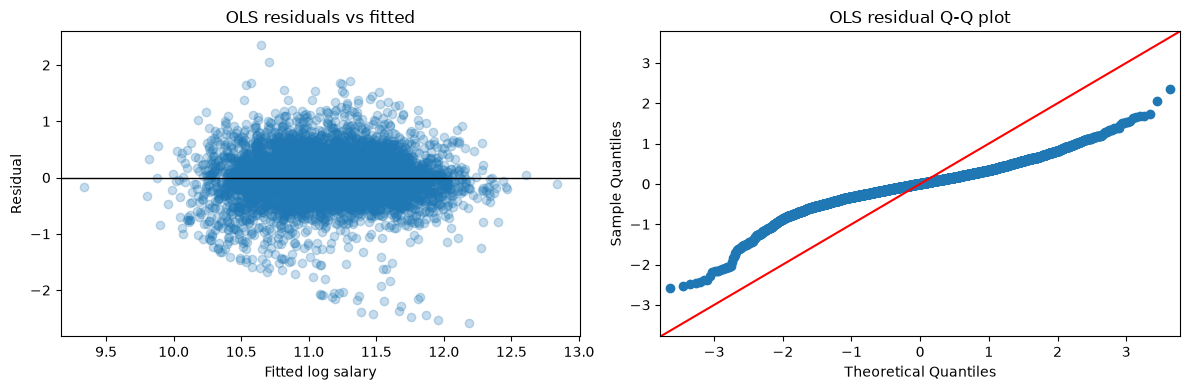

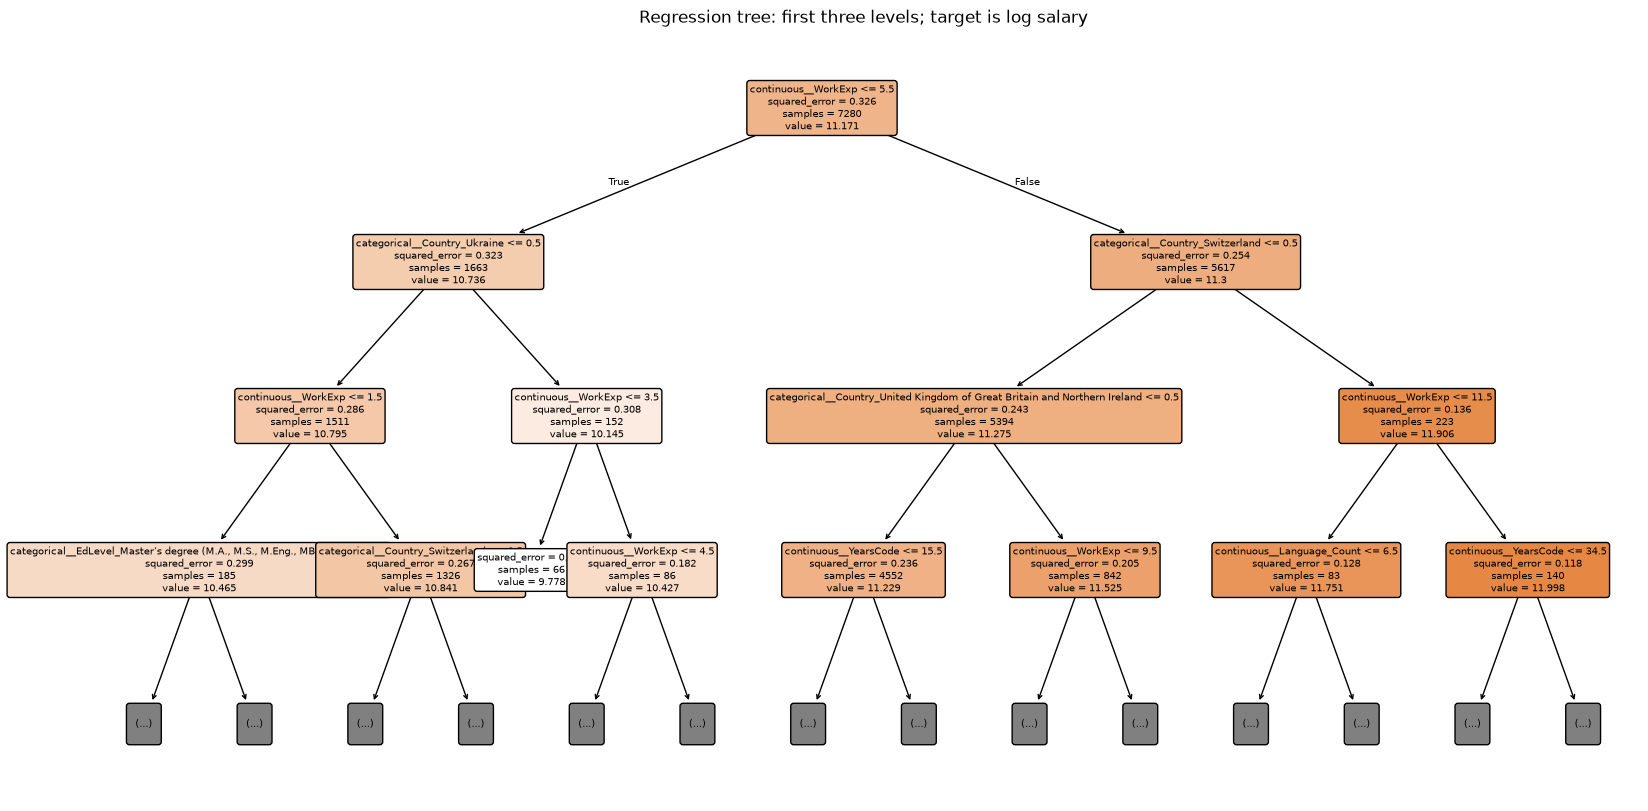

In [13]:
ols_preprocessor = make_preprocessor()
X_train_ols = ols_preprocessor.fit_transform(X_train)
ols_feature_names = ols_preprocessor.get_feature_names_out()
X_train_ols = pd.DataFrame(
    X_train_ols, columns=ols_feature_names, index=X_train.index
)
X_train_ols = sm.add_constant(X_train_ols, has_constant='add')
ols_inference = sm.OLS(np.log(y_train), X_train_ols).fit(cov_type='HC3')

print(f'OLS adjusted R-squared (log salary): {ols_inference.rsquared_adj:.4f}')
coefficient_table = pd.DataFrame({
    'Coefficient': ols_inference.params,
    'HC3_p_value': ols_inference.pvalues,
}).drop(index='const', errors='ignore')
top_coefficients = coefficient_table.reindex(
    coefficient_table['HC3_p_value'].sort_values().index
).head(25)
print(top_coefficients.to_string(float_format=lambda value: f'{value:.3g}'))

vif_features = ['WorkExp', 'YearsCode', 'Language_Count', 'Platform_Count']
vif_values = SimpleImputer(strategy='median').fit_transform(X_train[vif_features])
vif_frame = pd.DataFrame(vif_values, columns=vif_features, index=X_train.index)
vif_design = sm.add_constant(vif_frame, has_constant='add')
vif_table = pd.DataFrame({
    'Feature': vif_features,
    'VIF': [
        variance_inflation_factor(vif_design.to_numpy(), index)
        for index in range(1, vif_design.shape[1])
    ],
})
display(vif_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(ols_inference.fittedvalues, ols_inference.resid, alpha=0.25)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(title='OLS residuals vs fitted', xlabel='Fitted log salary', ylabel='Residual')
sm.qqplot(ols_inference.resid, line='45', ax=axes[1])
axes[1].set_title('OLS residual Q-Q plot')
plt.tight_layout()

tree_pipeline = fitted_models['Regression tree on log salary'].regressor_
tree_model = tree_pipeline.named_steps['regressor']
tree_feature_names = tree_pipeline.named_steps['preprocessor'].get_feature_names_out()
plt.figure(figsize=(20, 10))
plot_tree(
    tree_model, feature_names=tree_feature_names, max_depth=3,
    filled=True, rounded=True, fontsize=7,
)
plt.title('Regression tree: first three levels; target is log salary')
plt.show()

> Resource: Eurostat (2026). Comparative price levels of consumer goods and services – Household final consumption expenditure (Dataset: tec00120 / prc_ppp_ind_1, Reference year: 2025). European Commission.